# Kiểm tra khóa 1

Một notebook chạy hết và một file dự đoán hợp lệ là hai dấu mốc khác nhau. Còn một điểm validation đáng tin là dấu mốc thứ ba. Buổi này nối lại kiến thức từ Python tới feature engineering: ta theo một bài dữ liệu bảng từ đầu đến cuối và chỉ ra bằng chứng nào cần có trước khi tin kết quả. Bài làm của buổi kiểm tra nằm ở mục bài tập; trang này ôn lại cả quy trình bằng một ví dụ chạy được.

> **Mục tiêu sau buổi này**
>
> - Mô tả bài toán bằng đầu vào, target, metric và thông tin có ở thời điểm dự đoán.
> - Chọn split phản ánh tình huống mới, rồi xây baseline trong Pipeline.
> - Đọc một so sánh mô hình có kiểm soát và kiểm file nộp trước khi chạy dài.

## Đọc đề thành một quy trình

Giả sử cần dự đoán điểm một bài luyện mới của học sinh dựa trên điểm hai bài trước và số giờ tự học. Mỗi hàng là một lần đo. Nếu một học sinh có nhiều hàng, random split theo hàng có thể cho mô hình thấy người đó ở cả hai tập. Muốn đo khả năng dự đoán cho **học sinh mới**, ta phải chia theo người. Muốn dự đoán lần đo **tương lai** của những học sinh đã biết, ta phải mô phỏng đúng thời gian và lịch sử được phép dùng. Hai câu hỏi khác nhau thì không có lý do dùng chung một split.

Ở ví dụ dưới, mỗi hàng là một học sinh độc lập và dữ liệu được sinh từ công thức, nên random split hợp với giả định này. Đừng đem giả định ấy sang mọi dataset có cột tên giống nhau. Trước khi viết lệnh chia, hãy trả lời thành lời: “validation mới hơn train ở điểm nào?”



**Hỏi nhanh.** Mỗi học sinh có nhiều lần đo theo thời gian. Mục tiêu là dự đoán lần đo kế tiếp của chính những học sinh đã có trong dữ liệu. Chia dữ liệu thế nào cho đúng mục tiêu?

- A. Theo thời gian, validation là các lần đo sau mốc cắt
- B. Theo nhóm học sinh, lấy người mới làm validation
- C. Ngẫu nhiên từng hàng, theo tỉ lệ 80/20
- D. Sắp theo target rồi cắt phần cuối

<details><summary>Đáp án</summary>

A. Theo thời gian, validation là các lần đo sau mốc cắt

Học sinh thì không mới, chỉ lần đo là mới. Validation phải là các lần đo sau mốc cắt, và feature chỉ được dùng lịch sử trước mốc ấy. Chia theo nhóm học sinh là trả lời một câu hỏi khác: dự đoán cho người chưa từng thấy.

</details>

## Baseline và mô hình trên cùng dữ liệu

Ta sinh dữ liệu nhỏ có nhiễu, chia một test để riêng, rồi dùng các fold trên phần còn lại để so mô hình. Nhiễu được sinh ngẫu nhiên nên sai số trên train và test sẽ không trùng nhau tuyệt đối.

In [ ]:
import numpy as np
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

rng = np.random.default_rng(12)
X = rng.normal(size=(120, 3))
y = 6 + X @ np.array([1.2, 0.8, 0.3]) + rng.normal(0, 0.4, 120)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=4)
folds = list(KFold(3, shuffle=True, random_state=9).split(X_train))
candidates = {
    "median": DummyRegressor(strategy="median"),
    "ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.)),
}
for name, model in candidates.items():
    scores = -cross_val_score(model, X_train, y_train, cv=folds, scoring="neg_mean_absolute_error")
    print(name, "MAE từng fold:", scores.round(3).tolist(), "mean:", round(scores.mean(), 3))

median MAE từng fold: [1.362, 1.345, 1.22] mean: 1.309
ridge MAE từng fold: [0.352, 0.345, 0.252] mean: 0.316


Median baseline hợp MAE vì trung vị cực tiểu tổng độ lệch tuyệt đối. Dấu trừ trong scoring là quy ước của scikit-learn: score càng lớn càng tốt, nên negative MAE đổi trở lại thành MAE dương trước khi báo. Cả hai mô hình dùng đúng cùng fold, vì vậy chênh lệch không lẫn với việc một mô hình được chia tập dễ hơn.



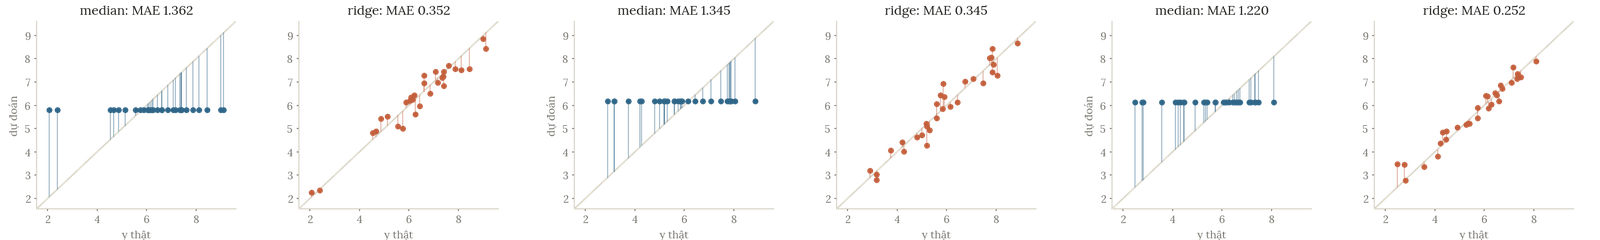

**Hỏi nhanh.** MAE của baseline median cao hơn Ridge trên cả ba fold. Ta kết luận được gì?

- A. Theo cách đánh giá này, Ridge tốt hơn
- B. Ridge chắc chắn thắng trên mọi dữ liệu tương lai
- C. Có thể xóa baseline khỏi nhật ký thí nghiệm
- D. Nên chia lại dữ liệu để Ridge thắng nhiều hơn

<details><summary>Đáp án</summary>

A. Theo cách đánh giá này, Ridge tốt hơn

Ridge thắng trên cả ba fold, nên với cách đánh giá này nó tốt hơn thật. Nhưng đó là bằng chứng trong một cách đánh giá cụ thể, chưa phải lời hứa cho mọi dữ liệu tương lai. Test độc lập và baseline vẫn phải được giữ trong nhật ký.

</details>

## Fit, dự đoán và kiểm đầu ra

Sau khi đã chọn cấu hình trên phần train/CV, ta fit lại trên toàn bộ phần train rồi chấm test một lần. Trong một đề thực tế, test dùng để nộp thường không có target; việc chấm ở dưới chỉ thực hiện được vì đây là thí nghiệm tổng hợp có nhãn để kiểm. Không có target thì không tự bịa test score.

**Hỏi nhanh.** Cross-validation đã chọn Ridge. Trước khi chấm test, bước tiếp theo đúng quy trình là gì?

- A. Giữ lại mô hình của fold có MAE thấp nhất
- B. Fit trên train cộng test cho nhiều dữ liệu
- C. Chọn lại `alpha` theo MAE trên test
- D. Fit lại cấu hình đã chọn trên toàn bộ train

<details><summary>Đáp án</summary>

D. Fit lại cấu hình đã chọn trên toàn bộ train

CV chọn ra một cấu hình, không chọn một bộ trọng số cụ thể. Fit lại trên toàn bộ train thì dùng hết dữ liệu được phép. Chọn fold đẹp nhất là nhặt lấy may mắn, còn đụng vào test thì test mất vai trò độc lập.

</details>

In [ ]:
selected = candidates["ridge"].fit(X_train, y_train)
predictions = selected.predict(X_test)
assert predictions.shape == y_test.shape
assert np.isfinite(predictions).all()
print("test MAE:", round(mean_absolute_error(y_test, predictions), 3))
sample_ids = np.arange(len(X_test)) + 1000
assert len(np.unique(sample_ids)) == len(sample_ids)
print("3 hàng đầu:", list(zip(sample_ids[:3].tolist(), predictions[:3].round(3).tolist())))

test MAE: 0.318
3 hàng đầu: [(1000, 8.359), (1001, 4.14), (1002, 6.358)]


Các assert chưa chứng minh đáp án giỏi; chúng kiểm một hợp đồng nhỏ: mỗi mẫu có đúng một dự đoán hữu hạn và ID không trùng trong ví dụ này. Đề có thể yêu cầu một xác suất cho mỗi lớp, thứ tự ID riêng hoặc một định dạng khác. Đọc hợp đồng của đề trước, rồi kiểm bằng chính sample submission hoặc checker được cấp nếu có.

## Khi kết quả bất thường

Train tốt, validation kém: kiểm độ phức tạp, split, feature có sẵn và phân phối. Train/validation cùng kém: kiểm baseline, target, metric, xử lý cột và khả năng mô hình biểu diễn quy luật. Điểm đột nhiên tăng rất mạnh sau một feature: hỏi feature dùng thông tin lúc nào; phép cải thiện có thể thật, cũng có thể chứa target hoặc tương lai.



Hình phần dư có cấu trúc là lý do để kiểm giả thuyết, không phải lệnh bắt buộc lấy log trong mọi bài. Shape sai, ID đổi thứ tự và metric sai hướng có thể làm mọi lựa chọn model phía sau vô nghĩa. Đọc dữ liệu nhỏ và vài hàng output bằng mắt vẫn là kỹ năng quan trọng trong phòng thi.

**Hỏi nhanh.** Một mô hình cây có MAE 0.30 trên train và 1.30 trên validation. Baseline median có MAE 1.31 trên validation. Hiểu kết quả này thế nào?

- A. Mô hình tốt, vì MAE trên train rất thấp
- B. Ngang baseline, cần kiểm overfit và cách đánh giá
- C. Metric bị đảo dấu, nên phải đọc ngược lại
- D. Chỉ cần thêm cây để MAE validation giảm xuống

<details><summary>Đáp án</summary>

B. Ngang baseline, cần kiểm overfit và cách đánh giá

Trên dữ liệu chưa thấy, mô hình gần như không hơn gì một hằng số. Khoảng cách lớn giữa train và validation gợi ý mô hình đang học thuộc. Trước khi tăng độ phức tạp, cũng cần kiểm cách chia, xem feature có sẵn lúc dự đoán không, và xem phân phối hai tập có giống nhau không.

</details>

## Tóm tắt

Quy trình hoàn chỉnh có bằng chứng ở từng bước: hiểu đề, split có lý do, baseline chạy được, so mô hình trên cùng fold, test để riêng, đầu ra đúng hợp đồng. Biết nhiều model giúp có thêm lựa chọn; giữ đúng quy trình giúp biết lựa chọn nào thật sự có ích.

## Kiểm tra cuối bài

**Câu 1.** Mỗi học sinh có 5 hàng, và ta cần đánh giá trên học sinh chưa từng thấy. Chia thế nào là phù hợp nhất?

- A. Ngẫu nhiên từng hàng
- B. Theo nhóm, mỗi học sinh là một nhóm
- C. Sắp theo target rồi chia
- D. Theo thời gian của lần đo

<details><summary>Đáp án</summary>

B. Theo nhóm, mỗi học sinh là một nhóm

Muốn đánh giá trên người mới thì mỗi học sinh phải nằm trọn ở một phía. Chia theo hàng thì cùng một người có mặt ở cả train lẫn validation, và điểm sẽ đẹp hơn thực tế.

</details>
**Câu 2.** Target trên train là `[1, 2, 2, 7, 8]`. Muốn một baseline hằng số tối ưu cho MAE, ta lấy giá trị nào từ train?

- A. 7
- B. 8
- C. 2
- D. 4

<details><summary>Đáp án</summary>

C. 2

Median là 2. Mean là 4, tối ưu cho MSE chứ không phải MAE. Baseline phải fit từ train, không lấy median của validation đang chấm.

</details>
**Câu 3.** Ba fold cùng số mẫu cho `neg_mean_absolute_error` lần lượt là $-0.3$, $-0.5$, $-0.7$. MAE trung bình cần báo là bao nhiêu?

- A. $-0.5$
- B. 1.5
- C. 2
- D. 0.5

<details><summary>Đáp án</summary>

D. 0.5

Đổi dấu rồi lấy trung bình: $(0.3 + 0.5 + 0.7)/3 = 0.5$. Ra $-0.5$ là quên đổi dấu, ra 1.5 là lấy tổng. Nếu các fold khác số mẫu mà muốn MAE gộp, phải lấy trung bình có trọng số theo số mẫu.

</details>
**Câu 4.** So hai mô hình, nhưng mỗi mô hình dùng một bộ fold khác nhau. Vì sao khó kết luận?

- A. Chênh lệch có thể đến từ độ khó của cách chia
- B. Fold khác nhau chỉ làm đổi thời gian chạy
- C. Mọi cách chia CV đều cho cùng một điểm
- D. Chỉ ảnh hưởng khi các lớp mất cân bằng

<details><summary>Đáp án</summary>

A. Chênh lệch có thể đến từ độ khó của cách chia

Mỗi bộ fold có độ khó riêng, nên chênh lệch có thể đến từ cách chia chứ không phải từ mô hình. Giữ nguyên các fold thì phần chênh còn lại mới là do mô hình hay feature.

</details>
**Câu 5.** Trong cross-validation, scaler được fit trên toàn bộ `X` trước khi chia. Làm vậy có vấn đề gì?

- A. Chỉ chạy chậm hơn một chút
- B. Không có vấn đề, vì scaler không dùng $y$
- C. Bước tiền xử lý đã học từ thống kê của validation
- D. Scaler kém chính xác hơn trên tập train

<details><summary>Đáp án</summary>

C. Bước tiền xử lý đã học từ thống kê của validation

Scaler fit trên toàn bộ `X` đã học trung bình và độ lệch chuẩn từ cả phần validation. Đặt scaler vào Pipeline để nó được fit lại trong từng fold, giữ việc học và việc chấm tách rời nhau.

</details>
**Câu 6.** File nộp mẫu có hai cột `id,target`, xếp theo `id` tăng dần. Trong notebook, `X_test` đã bị sắp lại theo một cột khác trước khi dự đoán. Ghi file thế nào cho an toàn?

- A. Ghi dự đoán theo thứ tự hiện tại của `X_test`
- B. Sắp các dự đoán tăng dần cho khớp với `id`
- C. Gắn `id` vào từng dự đoán, rồi merge theo file mẫu
- D. Bỏ cột `id`, vì máy chấm chỉ đọc cột target

<details><summary>Đáp án</summary>

C. Gắn `id` vào từng dự đoán, rồi merge theo file mẫu

Thứ tự hàng không phải là khóa, `id` mới là khóa. Gắn `id` vào từng dự đoán rồi merge theo file nộp mẫu, sau đó assert số hàng và tập `id` khớp nhau. Sai thứ tự là gán dự đoán cho mẫu khác, dù CV tốt đến đâu.

</details>
**Câu 7.** Một đoạn code tạo ra `pred` có shape `(30, 1)` và `y` có shape `(30,)`. Dòng nào vừa kiểm cùng số mẫu, vừa tính đúng MAE theo từng cặp?

- A. `np.abs(pred - y).mean()`, vì hai mảng cùng độ dài
- B. `np.abs(pred - y.T).mean()`, vì `.T` biến `y` thành cột
- C. `abs(pred.mean() - y.mean())`, để tránh broadcasting
- D. `np.abs(pred.ravel() - y).mean()`, sau khi kiểm độ dài

<details><summary>Đáp án</summary>

D. `np.abs(pred.ravel() - y).mean()`, sau khi kiểm độ dài

`pred - y` với shape `(30, 1)` và `(30,)` tạo ra ma trận $30 \times 30$ mà không báo lỗi. `.T` của một vector 1 chiều không đổi gì cả. `ravel` đưa cả hai về 1 chiều. Còn hiệu của hai trung bình thì không phải MAE.

</details>
**Câu 8.** Tập test độc lập đã được xem nhiều lần để chọn lại `alpha`. Nó còn là tập test độc lập không?

- A. Không, vì nó đã tham gia việc chọn, giống validation
- B. Còn, miễn là chưa từng fit trọng số trên nó
- C. Còn, nếu đã cố định seed từ đầu
- D. Còn, nếu mỗi lần chỉ xem một con số

<details><summary>Đáp án</summary>

A. Không, vì nó đã tham gia việc chọn, giống validation

Không fit trọng số trên test là chưa đủ. Mỗi lần nhìn test để chỉnh `alpha` là một lần học từ nó. Test đã thành validation, và điểm trên đó không còn khách quan.

</details>
**Câu 9.** Bài phân loại 10 lớp. Loss trên train giảm đều tới 0.01, nhưng accuracy trên validation đứng yên ở 10%, đúng bằng mức đoán ngẫu nhiên. Giả thuyết nào khớp nhất?

- A. Overfitting cực mạnh, do thiếu regularization
- B. Nhãn của train và validation được mã hóa lệch nhau
- C. Learning rate quá nhỏ nên mô hình chưa học được gì
- D. Rò rỉ dữ liệu trong train làm điểm train bị ảo

<details><summary>Đáp án</summary>

B. Nhãn của train và validation được mã hóa lệch nhau

Overfitting thường vẫn để lại chút tín hiệu trên validation. Đứng đúng ở mức ngẫu nhiên nghĩa là thứ mô hình học được không liên quan gì tới nhãn của validation. Nếu learning rate quá nhỏ thì loss train đã không xuống tới 0.01. Hãy kiểm cách đánh số các lớp, thứ tự file nhãn, và bước mã hóa nhãn ở cả hai tập trước khi chỉnh mô hình.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 284](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=107)

</details>
**Câu 10.** Đề chỉ cho `X_test` và yêu cầu nộp dự đoán, vậy mà notebook in ra `test MAE = 0.318`. Điều đầu tiên nên kiểm là gì?

- A. Tin con số này, vì code đã chạy hết
- B. Đổi sang mô hình mạnh hơn rồi chạy lại
- C. Nhãn dùng để tính MAE lấy từ đâu ra
- D. Tăng số cây để MAE giảm thêm

<details><summary>Đáp án</summary>

C. Nhãn dùng để tính MAE lấy từ đâu ra

Không có nhãn thật thì không thể tự tính MAE thật trên test. Con số kia có thể được tính từ nhãn validation, từ nhãn giả, hay từ một biến bị gán nhầm. Cần phân biệt điểm validation ở máy mình với điểm do máy chấm trả về.
Phỏng theo: [Google ML Crash Course · Overfitting quiz](https://developers.google.com/machine-learning/crash-course/overfitting/quiz)

</details>
## Đọc thêm

- [scikit-learn — Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html). Đọc cách tách đánh giá, lựa chọn mô hình và các kiểu split.
- [scikit-learn — Common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html). Đối chiếu leakage và preprocessing không nhất quán với Pipeline.